In [1]:
import numpy as np
import scipy as sp

import matplotlib.pyplot as plt

import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')

from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture

from analysis import analysis, model

%matplotlib inline

This doesnt really work -- the underlying data isn't reliably organized into separated gaussians, so we don't recover gaussians when fitting subsets

we should just let this go, as to fit many subsets is slow and we won't be able to show "stability" (reliable recovery from random subsets of data...)

In [349]:
fake_means = np.array([np.ones(64)*i for i in range(0,120,10)])
fake_covs = [np.eye(64)*0.5 for _ in range(12)]
fake_weights = np.ones(12)*(1/12)

In [350]:
mixture_model = BayesianGaussianMixture(n_components=12,
                        weight_concentration_prior_type='dirichlet_process',
                        weight_concentration_prior=1.e-8,
                        max_iter=200,
                        n_init=1,
                        warm_start=True,
                        random_state=0
                        )

mixture_model.means_ = fake_means
mixture_model.covariances_ = fake_covs
mixture_model.weights_ = fake_weights

fake_stack, components = mixture_model.sample(n_samples=30000)
fake_stack.shape

(30000, 64)

In [351]:
decoder = np.random.normal(size=(2,64))
decoded_samples = fake_stack @ decoder.T
decoded_samples.shape

(30000, 2)

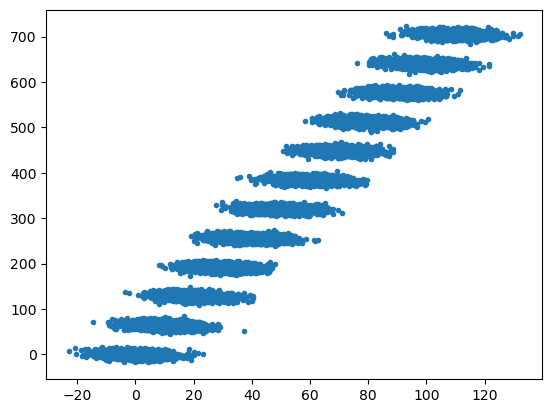

In [352]:
colormap = plt.colormaps["tab20"]
plt.plot(decoded_samples[:,0],decoded_samples[:,1],".")

In [404]:
# load a dataset of trial data for one subject

subject_idx = 29
chunk_indices = analysis.make_chunk_indices()
stack = analysis.load_trial_stack(subject_idx=subject_idx).transpose(0,1,3,2)

n_subset_samples = 5e3
n_subsets = 100

models = []

# samples x dimensions for each chunk, log'd 
chunk = 4
chunk_stack = analysis.log_emg_data(analysis.remove_nan_rows(stack[chunk_indices[chunk][0]:chunk_indices[chunk][1]+1].reshape(-1,64)))
# chunk_stack = fake_stack
# for N times:
for subset_i in range(n_subsets):
    # choose a random subset of samples
    chunk_subset_indices = np.random.choice(list(range(chunk_stack.shape[0])),int(n_subset_samples),replace=False)
    chunk_subset = chunk_stack[chunk_subset_indices]
    # fit a model to this subset
    mixture_model = BayesianGaussianMixture(n_components=12,
                            weight_concentration_prior_type='dirichlet_process',
                            weight_concentration_prior=1.e-8,
                            max_iter=200,
                            n_init=1,
                            warm_start=True,
                            random_state=0
                            )
    mixture_model.fit(chunk_subset)
    # save the params
    models.append(mixture_model)

In [395]:
# for each subset model fit (means and covs) except the last
# look at pairs of models
# find the pairs of components within each pair of models that are closest (up to wasserstein)
# model_pairs = model.closest_pairs_over_models_wasserstein(models)
model_pairs = model.closest_pairs_euclidean(models)
model_pairs = np.array(model_pairs)
# n_subsets-1 pairs, 12 components, 2 indexes
model_pairs.shape

(999, 12, 2)

In [396]:
paired_indexes = []
# for each of the pair "sequences" (length N)
# go through each component
# follow this component through the whole sequence
for component_idx in range(12):
    # go through each subset
    # for each 12x2 pairing
    component_index_sequence = []
    for pair_i, pairing in enumerate(model_pairs):
        # for each model in the sequence, and its neighbor
        current_model = models[pair_i]
        next_model = models[pair_i+1]

        # get the list of paired components through the sequence
        # for the first step, get both
        if pair_i == 0:
            current_component_idx = pairing[component_idx][0]
            next_component_idx = pairing[component_idx][1]
            component_index_sequence.append(current_component_idx)
            component_index_sequence.append(next_component_idx)
        else:
            current_component_idx = next_component_idx
            # find this idx in the next pairing
            current_location = np.where(pairing[:,0] == current_component_idx)[0][0]
            next_component_idx = pairing[current_location][1]
            component_index_sequence.append(next_component_idx)
    paired_indexes += [component_index_sequence]

paired_indexes = np.array(paired_indexes).T
paired_indexes.shape

(1000, 12)

In [397]:
# for each of the n_subset models, grab the means for each component
paired_means = []
for subset_i, pair_idx in enumerate(paired_indexes):
    component_means = []
    for component_idx in pair_idx:
        component_means.append(models[subset_i].means_[component_idx])
    paired_means.append(component_means)
paired_means = np.array(paired_means)
paired_means.shape

(1000, 12, 64)

In [398]:
paired_means.shape

(1000, 12, 64)

In [399]:
subsets = np.arange(1000)
components = np.arange(12)

In [400]:
import pandas as pd
midx = pd.MultiIndex.from_product([subsets, components])
paired_means_df = pd.DataFrame(paired_means.reshape(-1,64), index = midx)

import umap
reducer = umap.UMAP(n_components=2,n_neighbors=50,min_dist=0.5,metric='euclidean')
embedding = reducer.fit_transform(paired_means_df,)

In [401]:
embedding_df = pd.DataFrame(embedding, index=paired_means_df.index)

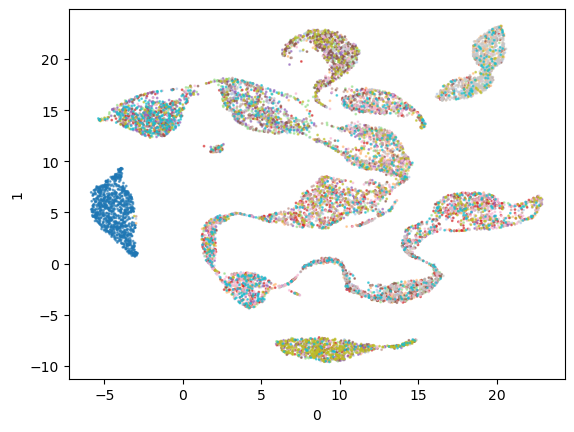

In [402]:
colormap = plt.colormaps["tab20"]
fig, ax = plt.subplots(1,1)
for ci, component_df in embedding_df.groupby(level=1):
        component_df.plot(kind="scatter",x=0,y=1,alpha=0.6,color=colormap(ci/12),ax=ax,s=np.ones(shape=(1000,)))

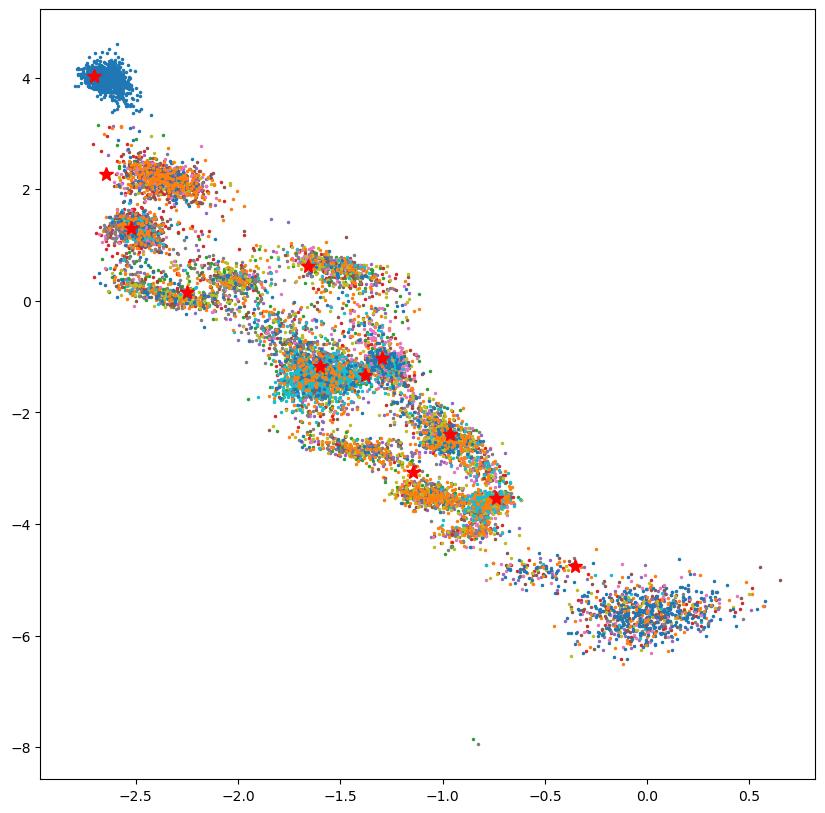

In [403]:

plt.figure(figsize=(10,10))
decoder = np.random.normal(size=(2,64))
decoded_means = paired_means @ decoder.T
decoded_means.shape
subject_models = model.load_log_trial_models(subject_idx)
for i in range(12):
    plt.plot(decoded_means[:,i,0],decoded_means[:,i,1],".",markersize=3)
decoded_model_means = subject_models[chunk].means_ @ decoder.T
plt.plot(decoded_model_means[:,0],decoded_model_means[:,1],"r*",markersize=10,label="Fitted Means")
decoded_samples = chunk_stack @ decoder.T

# test

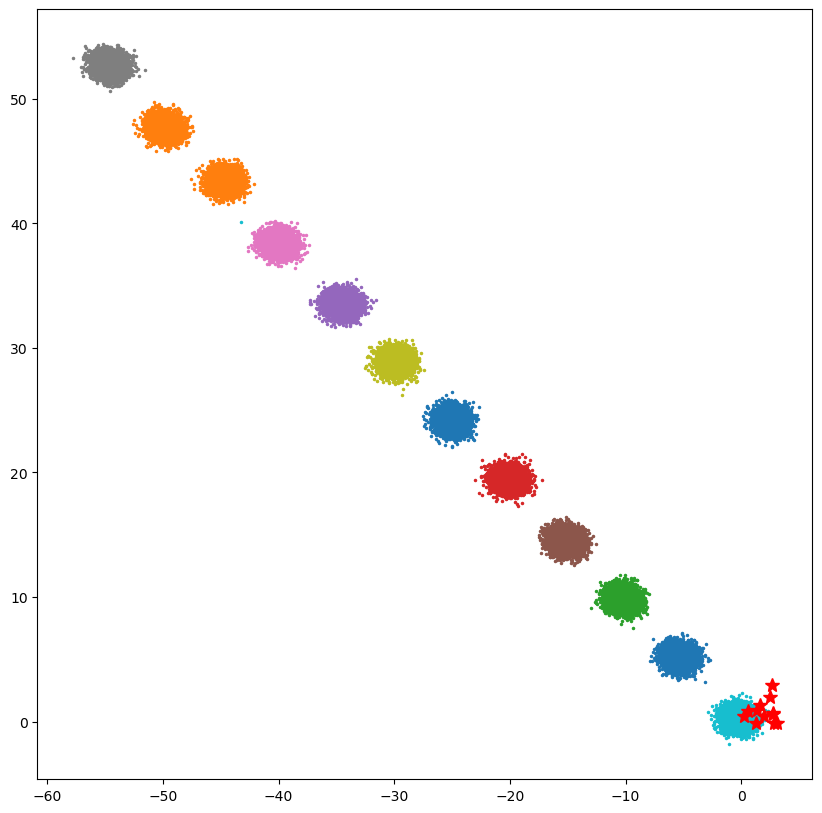

In [280]:
plt.figure(figsize=(10,10))
decoder = np.random.normal(size=(2,64))
decoded_means = paired_means @ decoder.T
decoded_means.shape
subject_models = model.load_log_trial_models(subject_idx)
for i in range(12):
    plt.plot(decoded_means[:,i,0],decoded_means[:,i,1],".",markersize=3)
decoded_model_means = subject_models[chunk].means_ @ decoder.T
plt.plot(decoded_model_means[:,0],decoded_model_means[:,1],"r*",markersize=10,label="Fitted Means")
decoded_samples = chunk_stack @ decoder.T

In [ ]:
# test == generate mixture gaussian data, try to recover params